# 07 - Final Model, Residual Analysis and Predictions

**Objective:** Examine where the selected model makes mistakes, save the fitted pipeline, reload it, and make predictions for new people through a reusable, validated function.

**Role in the ML workflow:** *Evaluation* (error analysis) and *GitHub / delivery* (a saved, reusable, documented model).

The model selected in notebook 06 by the documented rule is **OLS with the engineered features**.

### Concepts to understand first
* **Residual:** `actual - predicted`. A good model's residuals scatter randomly around zero with no pattern.
* **What residual patterns reveal:**
  * a *curve* in residuals vs predicted -> the relationship is not linear enough;
  * a *funnel* (spread grows with the prediction) -> errors are larger for expensive cases (heteroscedasticity);
  * residuals centred above/below zero for a group -> the model systematically under/over-predicts that group;
  * a very skewed or multi-peaked histogram -> some hidden subgroup is not modelled.
* **Serialising a model with `joblib`:** saving the *entire fitted pipeline* (feature creation, encoders, scaler if any, regression weights) to one file, so predictions later apply exactly the same steps.

## Setup

In [1]:
import sys
import warnings
from pathlib import Path

# Make the project root importable so we can use the code in src/.
# (Jupyter's working directory is notebooks/, so the project root is one level up.)
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

In [2]:
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings

from src.data_preprocessing import load_clean_data, split_data, MODEL_PATH, FIGURES_DIR, validate_features
from src.evaluate import evaluate_model, regression_metrics
from src.feature_engineering import ALL_ENGINEERED, AGE_BINS, AGE_LABELS
from src.train import build_ols_model, save_model
from src.predict import predict_charges, predict_dataframe, load_model, DISCLAIMER

sns.set_theme(style="whitegrid")
X_train, X_test, y_train, y_test = split_data(load_clean_data())

## Part A - Fit the selected model

In [3]:
final_model = build_ols_model(ALL_ENGINEERED).fit(X_train, y_train)   # fitted on TRAINING data only
evaluate_model("OLS (engineered)", final_model, X_train, y_train, X_test, y_test).round(4)

,Model,Dataset,RMSE,MAE,R2
0,OLS (engineered),Training,4428.2471,2352.6530,0.8568
1,OLS (engineered),Testing,4103.7132,2265.5276,0.9084


## Part B - Residual analysis (on the unseen test set)

The model is already fixed, so analysing its test residuals does not influence it.

In [4]:
test_pred = final_model.predict(X_test)
res = pd.DataFrame({
    "actual": y_test.values,
    "predicted": test_pred,
    "residual": y_test.values - test_pred,
    "smoker": X_test["smoker"].values,
    "age": X_test["age"].values,
    "bmi": X_test["bmi"].values,
})
res["age_group"] = pd.cut(res["age"], AGE_BINS, labels=AGE_LABELS, right=False)
res["abs_error"] = res["residual"].abs()
print("Mean residual:", round(res["residual"].mean(), 1), "| Median residual:", round(res["residual"].median(), 1))
print("Smallest predicted charge in test set:", round(res["predicted"].min(), 1))
res.head()

Mean residual: -72.9 | Median residual: -1247.9
Smallest predicted charge in test set: 2232.6


,actual,predicted,residual,smoker,age,bmi,age_group,abs_error
0,8688.85885,9919.484189,-1230.625339,no,49,22.515,40-49,1230.625339
1,5708.86700,8086.958467,-2378.091467,no,29,25.600,18-29,2378.091467
2,11436.73815,14004.058282,-2567.320132,no,51,36.385,50+,2567.320132
3,38746.35510,39103.258065,-356.902965,yes,31,34.390,30-39,356.902965
4,4463.20510,5462.767624,-999.562524,no,31,38.390,30-39,999.562524


### 1-3. Actual vs predicted, residuals vs predicted, residual distribution

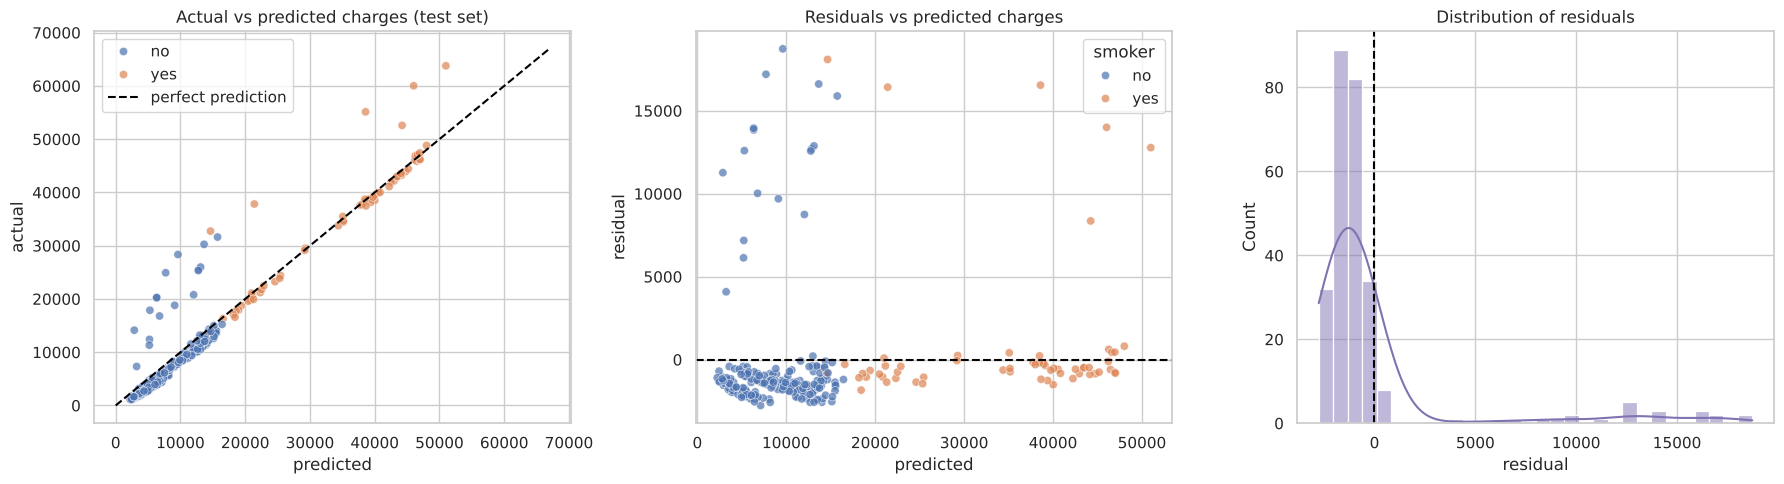

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

lim = [0, max(res["actual"].max(), res["predicted"].max()) * 1.05]
sns.scatterplot(data=res, x="predicted", y="actual", hue="smoker", alpha=0.7, ax=axes[0])
axes[0].plot(lim, lim, color="black", linestyle="--", label="perfect prediction")
axes[0].set_title("Actual vs predicted charges (test set)"); axes[0].legend()

sns.scatterplot(data=res, x="predicted", y="residual", hue="smoker", alpha=0.7, ax=axes[1])
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Residuals vs predicted charges")

sns.histplot(res["residual"], bins=30, kde=True, ax=axes[2], color="#8172B2")
axes[2].axvline(0, color="black", linestyle="--")
axes[2].set_title("Distribution of residuals")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "09_residual_overview.png", dpi=150, bbox_inches="tight")
plt.show()

**What the three plots show**
* **Actual vs predicted:** most points hug the diagonal. A distinct group lies well *above* it (actual charges much higher than predicted) - mostly non-smokers predicted at about 3,000-16,000 whose real charges are 15,000-32,000, plus a few smokers.
* **Residuals vs predicted:** the bulk of the residuals sit in a thin horizontal band (roughly -2,800 to +800) with **no curve and no funnel**, and a separate cluster of large positive residuals (about 4,000 to 19,000).
* **Histogram:** a tall peak just below zero and a long right tail. The mean residual is only about -73 but the median is about -1,248: the typical person is slightly *over*-predicted, while a minority is *strongly under*-predicted. The residuals are therefore not bell-shaped, which is another reason not to rely on the usual OLS confidence-interval formulas here (we do not use them).

**Is the relationship linear enough?** For the bulk of people, yes - there is no sign of curvature. The problem is not the *shape* of the fit but a group of people whose charges are far above what any of our six features can explain.

### Are errors larger for expensive cases?

In [6]:
res["predicted_band"] = pd.qcut(res["predicted"], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
band = res.groupby("predicted_band", observed=True).agg(
    n=("residual", "size"),
    mean_predicted=("predicted", "mean"),
    mean_residual=("residual", "mean"),
    MAE=("abs_error", "mean"),
)
band["MAE as % of mean predicted"] = 100 * band["MAE"] / band["mean_predicted"]
band.round(1)

,n,mean_predicted,mean_residual,MAE,MAE as % of mean predicted
predicted_band,,,,,
Q1 (lowest),67,4145.3,-650.7,1882.7,45.4
Q2,67,8007.6,-146.3,2637.1,32.9
Q3,67,12770.7,-101.6,2543.7,19.9
Q4 (highest),67,32456.1,607.0,1998.6,6.2


**Are errors larger for high-cost cases?** Not in absolute terms. MAE by predicted-charge quartile is about 1,883 / 2,637 / 2,544 / 1,999 - no funnel shape. In *relative* terms the picture reverses: the error is about 6% of the predicted charge for the most expensive quartile but about 45% for the cheapest, because a few low-predicted people turn out to cost far more than expected. There is only a mild systematic tilt (lowest quartile over-predicted by about 650 on average, highest quartile under-predicted by about 600).

In [7]:
# A closer look at the large errors: who are they and how much of the total error do they cause?
big = res["residual"] > 4000
print(f"Test cases with residual > 4,000: {big.sum()} of {len(res)} ({big.mean():.1%})")
print("   of which non-smokers:", int((res.loc[big, 'smoker'] == 'no').sum()), "| smokers:", int((res.loc[big, 'smoker'] == 'yes').sum()))
print(f"Share of the total squared error they cause: {(res.loc[big, 'residual'] ** 2).sum() / (res['residual'] ** 2).sum():.1%}")
rest = res.loc[~big, "residual"]
print(f"Everyone else: RMSE {np.sqrt((rest ** 2).mean()):,.0f}, MAE {rest.abs().mean():,.0f}, residual range {rest.min():,.0f} to {rest.max():,.0f}")

Test cases with residual > 4,000: 23 of 268 (8.6%)
   of which non-smokers: 17 | smokers: 6
Share of the total squared error they cause: 88.8%
Everyone else: RMSE 1,435, MAE 1,293, residual range -2,763 to 809


About 9% of people (23 of 268, mostly non-smokers) are under-predicted by more than 4,000, and they produce roughly 89% of the squared error. The other 91% are predicted to within about 1,300 on average (RMSE about 1,435). The same share (8.6%) of the *training* data shows large positive residuals, so this is a stable feature of the data, not bad luck in the test split.

This is the model's main limitation: some people have unusually high charges that **are not explained by age, sex, BMI, children, smoker or region**. The data contain no information (for example, medical history or claims) that would explain why, so we do not guess a cause. We also do not create arbitrary "high-charge" clusters to chase these cases: such a cluster would be defined using the target itself and could not be applied to a new person, whose charge is unknown.

### 4-5. Residuals by smoking status and by age group

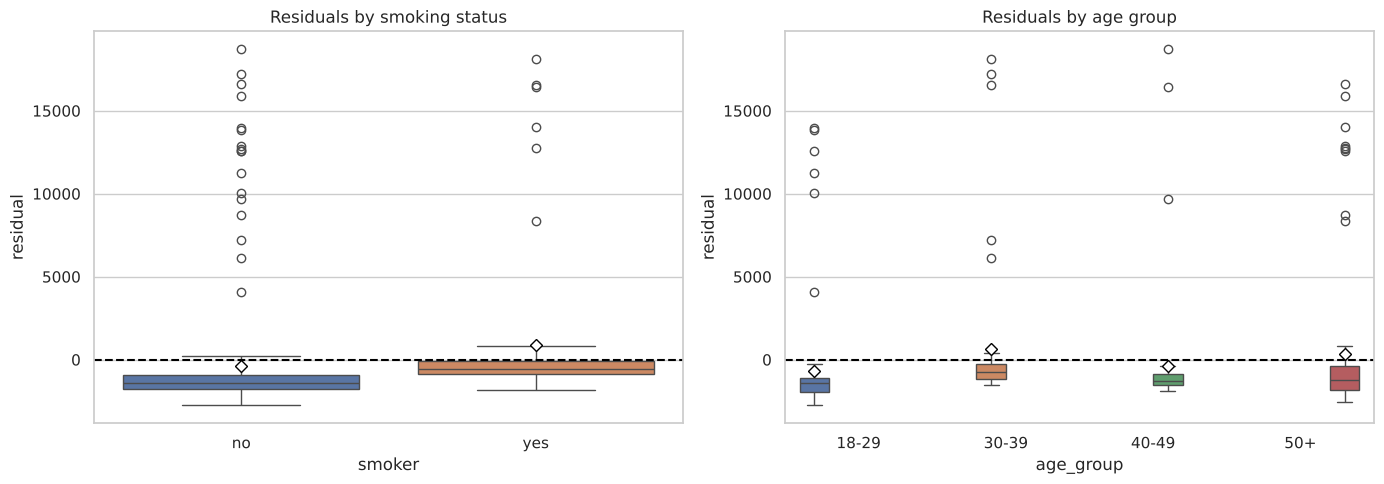

,count,mean,median,std
no,208,-357.0,-1386.0,3902.0
yes,60,910.0,-579.0,4668.0
18-29,82,-662.0,-1435.0,3452.0
30-39,48,670.0,-737.0,4612.0
40-49,58,-390.0,-1270.0,3741.0
50+,80,316.0,-1234.0,4606.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=res, x="smoker", y="residual", hue="smoker", legend=False, ax=axes[0], showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
axes[0].axhline(0, color="black", linestyle="--"); axes[0].set_title("Residuals by smoking status")
sns.boxplot(data=res, x="age_group", y="residual", hue="age_group", legend=False, ax=axes[1], showmeans=True,
            meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black"})
axes[1].axhline(0, color="black", linestyle="--"); axes[1].set_title("Residuals by age group")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "10_residuals_by_group.png", dpi=150, bbox_inches="tight")
plt.show()

summary = pd.concat([
    res.groupby("smoker", observed=True)["residual"].agg(["count", "mean", "median", "std"]),
    res.groupby("age_group", observed=True)["residual"].agg(["count", "mean", "median", "std"]),
])
summary.round(0)

**By smoking status:** non-smokers have mean residual about -357 (median about -1,386); smokers about +910 (median about -579), and smokers' errors are more spread out (standard deviation about 4,668 vs 3,902). **By age group:** mean residuals are about -662 (18-29), +670 (30-39), -390 (40-49) and +316 (50+), with medians all negative (about -740 to -1,435).

**Systematic under/over-prediction?** The differences between group means are a few hundred, small compared with the spread (standard deviations of 3,500-4,600) and based on only 48-82 people per age group, so there is **no convincing evidence of a systematic bias against any group**. The consistently negative *medians* reflect the pattern found above: the typical person is over-predicted by about 600-1,400 because the fit is pulled upward by the minority who cost far more than predicted.

### Do smokers show a different relationship between age, BMI and charges?

We saw in the EDA that they might. A rational segmentation is therefore **smokers vs non-smokers** (a variable whose effect on charges is huge, with a clear reason to believe the slopes differ) - not arbitrary charge clusters. To test whether separate models help, we compare them against the pooled models on the **same** test set.

In [9]:
def fit_by_group(features):
    """Fit one OLS model per smoking group on TRAINING rows; return test predictions in the original order."""
    preds = pd.Series(index=X_test.index, dtype=float)
    coefs = {}
    for group in ["no", "yes"]:
        tr = X_train["smoker"] == group
        te = X_test["smoker"] == group
        model = build_ols_model(features).fit(X_train[tr], y_train[tr])
        preds[te] = model.predict(X_test[te])
        names = model.named_steps["preprocess"].named_steps["encode_scale"].get_feature_names_out()
        coefs[group] = pd.Series(model.named_steps["model"].coef_, index=names)
    return preds, pd.DataFrame(coefs)

seg_preds, seg_coefs = fit_by_group(())          # separate models, ORIGINAL six features only
pooled_base = build_ols_model().fit(X_train, y_train)

comparison = pd.DataFrame({
    "Pooled OLS, 6 features":                 regression_metrics(y_test, pooled_base.predict(X_test)),
    "Separate smoker / non-smoker OLS":       regression_metrics(y_test, seg_preds),
    "Pooled OLS, engineered (selected)":      regression_metrics(y_test, test_pred),
}).T
print("Slopes learned separately for each group (per unit of the feature):")
print(seg_coefs.loc[["numeric__age", "numeric__bmi", "numeric__children"]].rename(columns={"no": "non-smokers", "yes": "smokers"}).round(1))
print()
comparison.round(4)

Slopes learned separately for each group (per unit of the feature):
                   non-smokers  smokers
numeric__age             262.6    258.3
numeric__bmi               8.2   1492.4
numeric__children        630.4    299.2



,RMSE,MAE,R2
"Pooled OLS, 6 features",5956.3429,4177.0456,0.8069
Separate smoker / non-smoker OLS,4635.4463,2842.1448,0.8831
"Pooled OLS, engineered (selected)",4103.7132,2265.5276,0.9084


**Do smokers have a different age/BMI/charges relationship?**
* **BMI: yes, dramatically.** Each extra BMI point adds about 8 to a non-smoker's predicted charges but about **1,492** to a smoker's.
* **Age: no.** The age slope is almost identical (about 263 vs 258 per year) - which agrees with `smoker_age` failing to help in notebook 03.
* Children: about 630 vs 299 per child; with the small groups this is probably noise.

**Does separate modelling pay off?** Against the pooled model with the same six original features, separate smoker / non-smoker models are much better (test RMSE 5,956 -> 4,635, R-squared 0.807 -> 0.883), so the segmentation had a sound rationale and works. But it does **not** beat the single pooled model with engineered features (RMSE about 4,104, R-squared 0.908), which captures the same smoker x BMI structure plus the BMI >= 30 step in one model. Two models to maintain, built on only about 200-ish smokers in training, for no gain: we do not adopt segmentation.

## Part C - Save the selected pipeline with `joblib`

The saved object is the **complete pipeline**: engineered-feature creation -> encoding -> OLS. Raw columns go in, a predicted charge comes out. Nothing is re-implemented at prediction time.

In [10]:
saved_path = save_model(final_model)
print("Saved:", saved_path.relative_to(PROJECT_ROOT), f"({saved_path.stat().st_size / 1024:.1f} KB)")

loaded = joblib.load(MODEL_PATH)
same = np.allclose(loaded.predict(X_test), final_model.predict(X_test))
print("Loaded model gives identical test predictions:", same)
print("Steps:", [name for name, _ in loaded.steps], "->", [name for name, _ in loaded.named_steps['preprocess'].steps])

Saved: models/medical_insurance_model.joblib (5.7 KB)
Loaded model gives identical test predictions: True
Steps: ['preprocess', 'model'] -> ['add_features', 'encode_scale']


**Important:** the pipeline contains a reference to our function `add_engineered_features` in `src/feature_engineering.py`. `joblib` stores the *name* of that function, not its code. To load the model you therefore need (a) the `src/` folder importable and (b) a compatible scikit-learn version. This is one of several reasons a saved file is not automatically "production ready" - see the limitations below.

## Part D - Predictions for new people

New observations must be a DataFrame with the **same raw columns** the model was trained on. `predict_charges` (in `src/predict.py`) validates the input first and then calls the saved pipeline.

In [11]:
new_people = pd.DataFrame([
    {"age": 25, "sex": "female", "bmi": 22.0, "children": 0, "smoker": "no",  "region": "southwest"},
    {"age": 45, "sex": "male",   "bmi": 31.5, "children": 2, "smoker": "yes", "region": "southeast"},
    {"age": 60, "sex": "female", "bmi": 27.0, "children": 1, "smoker": "no",  "region": "northeast"},
    {"age": 45, "sex": "male",   "bmi": 24.0, "children": 2, "smoker": "yes", "region": "southeast"},
])
out = new_people.copy()
out["estimated_charges"] = predict_dataframe(new_people).round(2)
out

,age,sex,bmi,children,smoker,region,estimated_charges
0,25,female,22.0,0,no,southwest,4393.70
1,45,male,31.5,2,yes,southeast,40536.83
2,60,female,27.0,1,no,northeast,14977.15
3,45,male,24.0,2,yes,southeast,22147.11


**Sanity check against the EDA:** the non-smokers are estimated at about 4,400 and 15,000, in line with non-smokers' typical charges (median about 7,300 in the data); the smoker is estimated at about 40,500, in line with smokers' charges (median about 34,500).

**The interaction in action:** rows 2 and 4 are identical except for BMI (31.5 vs 24.0) - both are smokers. The model's estimate drops from about 40,537 to about 22,147, a difference of about 18,400 from BMI alone. For an otherwise identical *non-smoker*, the same BMI change shifts the estimate by only about 70 (9,729 vs 9,659). That is the smoker x obesity pattern the model learned. These figures are model estimates for illustration, not statements about real people.

### Using the reusable function

In [12]:
estimate = predict_charges(age=35, sex="male", bmi=27.5, children=2, smoker="no", region="northwest")
print(f"Estimated annual charge: {estimate:,.2f}")
print()
print(DISCLAIMER)

Estimated annual charge: 6,717.17

Estimates come from a simple statistical model trained on a small public dataset. They are NOT insurance quotes, guaranteed prices or medical advice.


### Input validation and error handling

In [13]:
bad_inputs = {
    "unknown smoker value":     dict(age=30, sex="male", bmi=25, children=0, smoker="sometimes", region="northeast"),
    "negative age":             dict(age=-5, sex="male", bmi=25, children=0, smoker="no", region="northeast"),
    "text instead of a number": dict(age=30, sex="male", bmi="heavy", children=0, smoker="no", region="northeast"),
    "missing value":            dict(age=30, sex="male", bmi=None, children=0, smoker="no", region="northeast"),
    "unknown region":           dict(age=30, sex="male", bmi=25, children=0, smoker="no", region="atlantis"),
}
for label, person in bad_inputs.items():
    try:
        predict_charges(**person)
        print(f"{label:26s} -> accepted (unexpected!)")
    except ValueError as err:
        print(f"{label:26s} -> rejected: {err}")

# Valid but outside the age range seen in training: allowed with a warning, because the model would extrapolate
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    value = predict_charges(age=80, sex="female", bmi=25, children=0, smoker="no", region="northeast")
print(f"\nAge 80 -> {value:,.2f}  | warning: {caught[0].message if caught else None}")

unknown smoker value       -> rejected: Column 'smoker' has invalid values ['sometimes']. Allowed: ['no', 'yes']
negative age               -> rejected: Column 'age' must be between 0 and 120.
text instead of a number   -> rejected: Column 'bmi' must be numeric.
missing value              -> rejected: Missing values found in columns: ['bmi']
unknown region             -> rejected: Column 'region' has invalid values ['atlantis']. Allowed: ['northeast', 'northwest', 'southeast', 'southwest']

Age 80 -> 19,671.58  | warning: 'age' is outside the training range [18, 64]; the prediction is an extrapolation and may be unreliable.


### Importing the function from another Python script

`src/predict.py` can be used from any script run from the project root. Here a **separate Python process** imports it, which is what another script would do:

In [14]:
script = '''
from src.predict import predict_charges
print(round(predict_charges(age=52, sex="female", bmi=29.3, children=3, smoker="no", region="northwest"), 2))
'''
result = subprocess.run(["python", "-c", script], cwd=PROJECT_ROOT, capture_output=True, text=True)
print("stdout:", result.stdout.strip() or "(none)")
print("stderr:", result.stderr.strip()[-300:] or "(none)")

stdout: 13997.69
stderr: (none)


## Limitations - why the saved model is *not* production-ready

* Trained on a **small public dataset** (1,337 people) of unknown origin; the data's collection method, time period and currency are not documented.
* Only ages 18-64 and BMI 16-53 were seen; outside that the model extrapolates.
* A **linear** model with a handful of hand-built interactions; the residuals above show errors remain, especially for some high-cost cases.
* No fairness or bias audit has been done; using sex or region in real pricing could be inappropriate or illegal.
* No monitoring, versioning, retraining plan or security review; the pickle-based `.joblib` format must only be loaded from trusted sources.
* Predictions are **estimates for learning purposes** - not insurance quotes, guaranteed prices or medical advice.

## Common errors and fixes
| Error | Cause | Fix |
|---|---|---|
| `ModuleNotFoundError: src` when loading the model | `src/` not importable | run from the project root, or add it to `sys.path` as in the setup cell |
| `FileNotFoundError: ...joblib` | model not trained yet | run `python -m src.train` (or this notebook) |
| `ValueError: Missing required columns` | wrong or misspelt column names | use exactly `age, sex, bmi, children, smoker, region` |
| scikit-learn version warnings on load | model saved with a different version | retrain with your installed version |

## Practical task
1. Predict charges for yourself (or a fictional person) and then change only `smoker` - how large is the difference?
2. Predict a 50-year-old with BMI 35, once as non-smoker and once as smoker. Compare the *difference* with the difference at BMI 22. What does that show about the interaction?
3. Add one more invalid-input test to `tests/test_preprocessing.py` and run `python -m pytest -v`.